In [ ]:
import pandas as pd

df = pd.read_csv("../new_dataset.csv")

In [2]:
df['chords'][0]

'<intro_1> Db Gb Db Eb7 Ab7 Db Ab7 Db Ab7 Db Gb Db Bbmin7 Eb7 Ab7 Db Ab7 Gb Ab7 Db <verse_1> Ab7 Db Ebmin7 Ab7 Ab Db Ab7 Db <verse_2> Ab7 Db Ebmin7 Ab7 Gb Eb7 Ab Db Eb7 Ab7 Db Ab7 Db Ab Bbmin F7 Bbmin F7 Bbmin Gb Eb7 Db Eb7 Ab7 Db <chorus_1> Ab7 Db Ab7 Db Gb Db Eb7 Ab7 Db Ab7 Db Ab Db <verse_3> Ab Db Ebmin7 Ab7 Ab Db Ab7 Db <verse_4> Ab7 Db Db7 Gb Eb7 Db Bb7 Eb7 Ab7 Db Ab7 Db Ab Bbmin F7 Bbmin F7 Bbmin Gb Eb7 Db Eb7 Ab7 Db <chorus_2> Ab7 Db Ab7 Db Gb Db Eb7 Ab7 Db'

In [5]:
df["unique_chords"] = df["chords"].apply(
    lambda chords: [
        chord
        for chord in dict.fromkeys(chords.split())
        if not chord.startswith("<")
    ]
)

In [6]:
df["unique_chords"]

0        [Db, Gb, Eb7, Ab7, Bbmin7, Ebmin7, Ab, Bbmin, ...
1                                          [G, Emin, C, D]
2                                [D, G, C, Fs, E, B, A, F]
3                                    [Dmin, C, G, F, Amin]
4        [Fmin, Gmin, Dmin, C, Bb, F, Cmin, Dmin7, G, C...
                               ...                        
13574      [G, D, C, Amin, F, Amin7, A, Bmin, Emin, Asus4]
13575                 [A, Fsmin, D, E, Csmin, E/Gs, Asus4]
13576                [C, Emin, Dmin, G, F, Amin, C/E, G/B]
13577                     [Dmin, C, Gmin, Bb, Amin, F, A7]
13578    [Amaj7, Dmaj7, G7, Csmin, Bmin, C/E, G, C, Emi...
Name: unique_chords, Length: 13579, dtype: object

In [14]:
df['year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

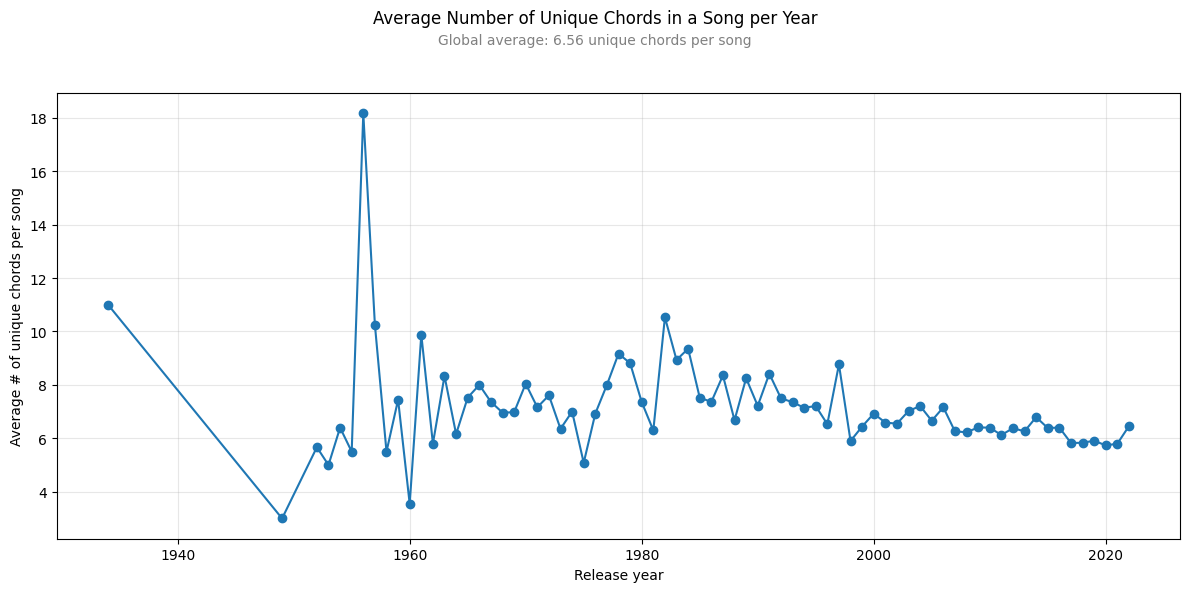

In [25]:
import matplotlib.pyplot as plt

df["unique_chord_count"] = df["unique_chords"].str.len()
global_average = df["unique_chord_count"].mean()

average_chords_by_year = (
    df.groupby("year")["unique_chord_count"]
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(average_chords_by_year.index, average_chords_by_year.values, marker="o")

fig.suptitle("Average Number of Unique Chords in a Song per Year")
fig.text(
    0.5, 0.94,
    f"Global average: {global_average:.2f} unique chords per song",
    ha="center",
    va="top",
    fontsize=10,
    color="gray"
)

# Remove the ax.set_title(...) call
fig.tight_layout(rect=[0, 0, 1, 0.90])

ax.set(
    xlabel="Release year",
    ylabel="Average # of unique chords per song",
)
ax.grid(True, alpha=0.3)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig("../visualizations/unique_chords_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

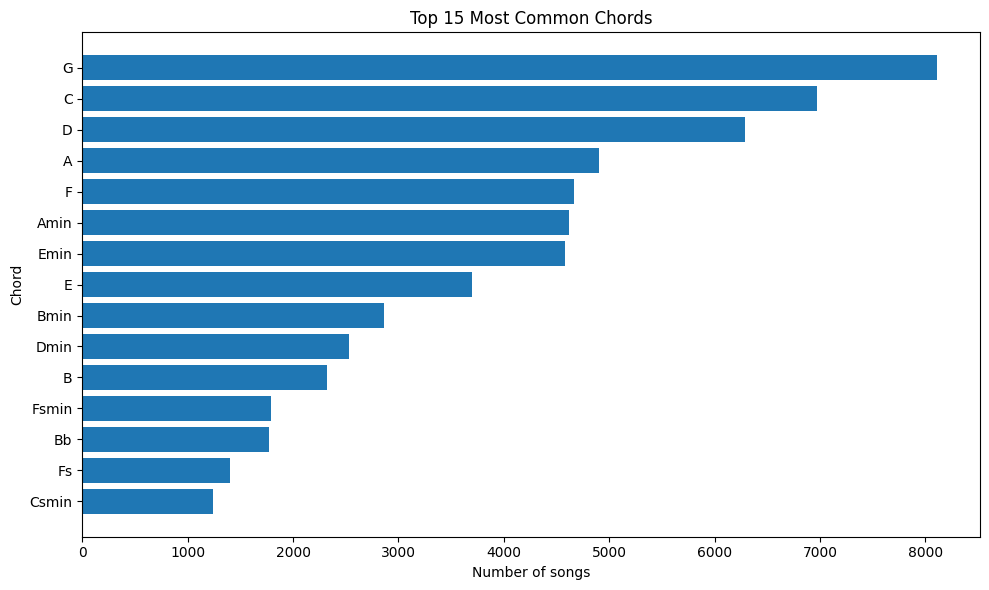

In [28]:
chord_counts = df["unique_chords"].explode().value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(chord_counts.index, chord_counts.values)
ax.invert_yaxis()

ax.set(
    title="Top 15 Most Common Chords",
    xlabel="Number of songs",
    ylabel="Chord",
)
fig.tight_layout()
fig.savefig("../visualizations/top_common_chords.png", dpi=150, bbox_inches="tight")
plt.show()

## Data Cleaning/Preprocessing with Final Dataset

In [2]:
import pandas as pd

df = pd.read_csv("../chordonomicon_spotifydump_join.csv.gz", compression='gzip', low_memory=False)

In [7]:
df["unique_chords"] = df["chords"].apply(
    lambda chords: [
        chord
        for chord in dict.fromkeys(chords.split())
        if not chord.startswith("<")
    ]
)

In [8]:
df['year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

In [10]:
df.drop(columns='Unnamed: 0', inplace=True)

In [ ]:
df.loc[df['year'].isna(), 'year'] = df['release_date']

In [24]:
def extract_roots(chords):
    if isinstance(chords, str):
        chords = chords.strip().strip("[]").split(",")
    elif not isinstance(chords, (list, tuple)):
        return []

    roots = []
    for chord in chords:
        if not isinstance(chord, str):
            continue

        chord = chord.strip().strip("'\"")
        if chord:
            root = chord[:2] if len(chord) > 1 and chord[1] == "b" else chord[0]
            if root not in roots:
                roots.append(root)

    return roots

df["chord roots"] = df["unique_chords"].apply(extract_roots)

In [25]:
df.head()

,id,chords,release_date,genres,decade,rock_genre,artist_id,main_genre,spotify_song_id,spotify_artist_id,track,popularity,uri,db_artist_id,artist,unique_chords,year,chord roots
0,2,<intro_1> E D A/Cs E D A/Cs <verse_1> E D A/Cs...,2003-01-01,'alternative metal' 'alternative rock' 'nu met...,2000.0,pop rock,artist_2,metal,2ffJZ2r8HxI5DHcmf3BO6c,694QW15WkebjcrWgQHzRYF,I Want To Die A Beautiful Death,12.0,spotify:track:2ffJZ2r8HxI5DHcmf3BO6c,694QW15WkebjcrWgQHzRYF,Everclear,"[E, D, A/Cs, A, C, G]",2003.0,"[E, D, A, C, G]"
1,3,<intro_1> Csmin <verse_1> A Csmin A Csmin A Cs...,2003-01-01,'alternative metal' 'canadian rock' 'funk meta...,2000.0,canadian rock,artist_3,metal,5KiY8SZEnvCPyIEkFGRR3y,0niJkG4tKkne3zwr7I8n9n,Sad Exchange,28.0,spotify:track:5KiY8SZEnvCPyIEkFGRR3y,0niJkG4tKkne3zwr7I8n9n,Finger Eleven,"[Csmin, A, B, Fsmin, Dsmin, Gsmin, Cs]",2003.0,"[C, A, B, F, D, G]"
2,13,<intro_1> D G D G D G D G D G D Bb C D G D Bb ...,2009-11-13,'australian alternative rock' 'australian rock',2000.0,australian alternative rock,artist_10,rock,3ouHmB2wtv5CzbsWlAGZzq,6LBCQo20ri3tsvbsWWLmr6,Iberian Dream,26.0,spotify:track:3ouHmB2wtv5CzbsWlAGZzq,6LBCQo20ri3tsvbsWWLmr6,Powderfinger,"[D, G, Bb, C, A]",2009.0,"[D, G, Bb, C, A]"
3,14,<intro_1> E G D A <verse_1> D A D A D A D A <c...,2011-09-20,'comic',2010.0,NaN,artist_11,NaN,3uKv45soturBZVumfsXoag,292sg99iIOc93zcd30r4Oz,Glasses,29.0,spotify:track:3uKv45soturBZVumfsXoag,292sg99iIOc93zcd30r4Oz,Jonathan Coulton,"[E, G, D, A, Bmin]",2011.0,"[E, G, D, A, B]"
4,16,<intro_1> D F C D F C D F C D F C D <verse_1> ...,2000,'art punk' 'permanent wave' 'protopunk' 'singe...,1990.0,NaN,artist_13,punk,2YNNsFj1otPsgN6nQus2So,0vYkHhJ48Bs3jWcvZXvOrP,One Voice,11.0,spotify:track:2YNNsFj1otPsgN6nQus2So,0vYkHhJ48Bs3jWcvZXvOrP,Patti Smith,"[D, F, C, Emin, G, A, Bb, C/E]",2000,"[D, F, C, E, G, A, Bb]"


In [27]:
def has_chord_with_second_char(value, char):
    if isinstance(value, str):
        chords = value.strip().strip("[]").split(",")
    elif isinstance(value, (list, tuple, set)):
        chords = value
    else:
        return False

    return any(
        isinstance(chord, str)
        and chord.strip().strip("'\"")[1:2] == char
        for chord in chords
    )

mask = df["unique_chords"].apply(
    lambda value: has_chord_with_second_char(value, "b")
)
df.loc[mask, ["unique_chords"]]

,unique_chords
2,"[D, G, Bb, C, A]"
4,"[D, F, C, Emin, G, A, Bb, C/E]"
5,"[C, Bb, F, G, D, E, A]"
7,"[Fmin7, Cmin7, Bbmin9, Dbmaj7, F/G, Eaug/Gb, F..."
9,"[Db, Gb, Eb7, Ab7, Bbmin7, Ebmin7, Ab, Bbmin, ..."
...,...
187226,"[Cmin, Bb, Eb, Ab, Gmin, Fmin]"
187227,"[E, E7, A, D, A7, F, Bb, F7, Eb, Bb7]"
187233,"[Cmin, G, G13b, Ab/Bb, Ebmaj7, Ddim7, G7, F]"
187234,"[F, Dmin, Amin, Bb, C, A, Gmin]"


In [28]:
df.iloc[184417]

id                                                              624713
chords               <intro_1> Csmin Fsmin A B <chorus_1> Csmin Fsm...
release_date                                                2018-09-28
genres               'dance pop' 'edm' 'electronic trap' 'pop' 'pop...
decade                                                          2010.0
rock_genre                                                         NaN
artist_id                                                 artist_39092
main_genre                                                         pop
spotify_song_id                                 4w8niZpiMy6qz1mntFA5uM
spotify_artist_id                               540vIaP2JwjQb9dm3aArA4
track                   Taki Taki (with Selena Gomez, Ozuna & Cardi B)
popularity                                                        97.0
uri                               spotify:track:4w8niZpiMy6qz1mntFA5uM
db_artist_id         0C8ZW7ezQVs4URX5aX7Kqx, 1i8SpTcr7yvPOmcqrbnVXY...
artist

In [29]:
df.iloc[184417]['chords']

'<intro_1> Csmin Fsmin A B <chorus_1> Csmin Fsmin A B Csmin Fsmin A B Csmin <interlude_1> Fsmin A B Csmin Fsmin A B <chorus_2> Csmin Fsmin A B Csmin Fsmin A B Csmin <verse_1> Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B <chorus_3> Csmin Fsmin A B Csmin Fsmin A B Csmin <interlude_2> Fsmin A B Csmin Fsmin A B <verse_2> Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B <chorus_4> Csmin Fsmin A B Csmin Fsmin A B Csmin <interlude_3> Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin <interlude_4> Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin Fsmin A B Csmin'